<a href="https://colab.research.google.com/github/Nireida/ag-grid-task/blob/master/Tema3_ejercicios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tema 3: Datasets, Dataloaders y collate functions

In [45]:
from torchvision import transforms, datasets
from torchvision.transforms import Lambda
from torch.utils.data import DataLoader
import torch

import matplotlib.pyplot as plt
import torch.nn.functional as F

import pandas as pd
import numpy as np
import torch


from torch.utils.data import Dataset, DataLoader
import time
import random

## 1. Crear un Dataloader para el dataset Fashion MNIST

### Crear un Transform para el conjunto de entrenamiento que:
*   Cambie el tamaño de las muestras a 80x80
*   Data augmentation:
  * Volteo horizontal (probabilidad de 0.5)
  * Volteo vertical (probabilidad de 0.5)
  * Recorte aleatorio de secciones de 75x75
  * Rotación aleatoria de 10 grados
*   Pasar a tensor
*   Normalizar

### Crear un Transform para el conjunto de test que:

*   Cambie el tamaño de las muestras a 80x80
*   Pasar a tensor
*   Normalizar




In [46]:
transform_train = transforms.Compose([
    transforms.Resize((80, 80)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomCrop((75, 75)),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

transform_test = transforms.Compose([
    transforms.Resize((80, 80)),
    transforms.ToTensor(),
    Lambda(lambda x: x / 255.0)
])

### Crear el Dataset aplicando el transform para entrenamiento y test

In [47]:
train_dataset = datasets.FashionMNIST(
  root='data', train=True, transform=transform_train, download=True
)
print(len(train_dataset.classes))

10


In [48]:
test_dataset = datasets.FashionMNIST(
   root='data', train=False, transform=transform_test, download=True
)


### Visualizar un conjunto de muestras de entrenamiento y test

In [49]:
import matplotlib.pyplot as plt

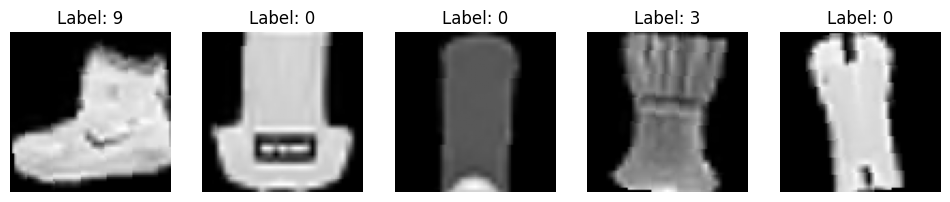

In [50]:
fig, axes = plt.subplots(1, 5, figsize=(12, 6))
for i in range(5):
    image, label = train_dataset[i]
    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {label}")
    axes[i].axis('off')
plt.show()

In [51]:
from torch.utils.data import DataLoader

### Crear una función de collate que separe muestra y etiquetas y transforma las etiquetas categóricas en una representación one-hot encoded

In [52]:
def custom_collate_fn(data):
  images_collate = [item[0] for item in data]
  labels_collate = [item[1] for item in data]

  images_collate = torch.stack(images_collate)
  labels_one_hot = F.one_hot(torch.tensor(labels_collate), num_classes=10).float()
  return images_collate, labels_one_hot

### Crear un dataloader con la collate_fn y además que utilice num_workers y prefetch_factor

In [53]:
train_loader = DataLoader(train_dataset, batch_size=5, shuffle=True, collate_fn = custom_collate_fn)
test_loader = DataLoader(test_dataset, batch_size=5, shuffle=False, collate_fn = custom_collate_fn)

### Crear un loop del dataloader y mostrar 2 muestras por cada época.

In [54]:
for i, batch in enumerate(train_loader):
  print(f"Batch{i}")
  print(batch)
  x, y = batch
  break

print(f"x: {x}, y: {y}")

Batch0
(tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0

## 2. Crear un Dataloader para un dataset tabular propio

In [55]:
np.random.seed(42)


features_class_0 = np.random.rand(10, 10)
features_class_1 = np.random.rand(10, 10) + 1


labels_class_0 = np.zeros(10, dtype=int)
labels_class_1 = np.ones(10, dtype=int)


features = np.vstack((features_class_0, features_class_1))
labels = np.concatenate((labels_class_0, labels_class_1))


data_tr = pd.DataFrame(features, columns=[f'feature_{i+1}' for i in range(features.shape[1])])
data_tr['label'] = labels

In [56]:
np.random.seed(36)


features_class_0 = np.random.rand(5, 10)
features_class_1 = np.random.rand(5, 10) + 1


labels_class_0 = np.zeros(5, dtype=int)
labels_class_1 = np.ones(5, dtype=int)


features = np.vstack((features_class_0, features_class_1))
labels = np.concatenate((labels_class_0, labels_class_1))


data_te = pd.DataFrame(features, columns=[f'feature_{i+1}' for i in range(features.shape[1])])
data_te['label'] = labels

In [57]:
data_tr

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,label
0,0.374540,0.950714,0.731994,0.598658,0.156019,0.155995,0.058084,0.866176,0.601115,0.708073,0
1,0.020584,0.969910,0.832443,0.212339,0.181825,0.183405,0.304242,0.524756,0.431945,0.291229,0
2,0.611853,0.139494,0.292145,0.366362,0.456070,0.785176,0.199674,0.514234,0.592415,0.046450,0
3,0.607545,0.170524,0.065052,0.948886,0.965632,0.808397,0.304614,0.097672,0.684233,0.440152,0
4,0.122038,0.495177,0.034389,0.909320,0.258780,0.662522,0.311711,0.520068,0.546710,0.184854,0
5,0.969585,0.775133,0.939499,0.894827,0.597900,0.921874,0.088493,0.195983,0.045227,0.325330,0
6,0.388677,0.271349,0.828738,0.356753,0.280935,0.542696,0.140924,0.802197,0.074551,0.986887,0
7,0.772245,0.198716,0.005522,0.815461,0.706857,0.729007,0.771270,0.074045,0.358466,0.115869,0
8,0.863103,0.623298,0.330898,0.063558,0.310982,0.325183,0.729606,0.637557,0.887213,0.472215,0
9,0.119594,0.713245,0.760785,0.561277,0.770967,0.493796,0.522733,0.427541,0.025419,0.107891,0


In [58]:
data_te

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,label
0,0.728507,0.601614,0.952181,0.143173,0.807359,0.363215,0.186557,0.259151,0.629762,0.032561,0
1,0.947232,0.904318,0.550130,0.197008,0.232033,0.002366,0.226056,0.375343,0.452744,0.246079,0
2,0.460127,0.210407,0.670889,0.451769,0.592685,0.327012,0.223990,0.215618,0.171685,0.022679,0
3,0.629069,0.531413,0.243392,0.524828,0.174228,0.341936,0.998178,0.232437,0.025417,0.150733,0
4,0.483185,0.353762,0.639769,0.419413,0.187010,0.351765,0.482242,0.802009,0.402824,0.437993,0
5,1.873042,1.196441,1.721717,1.680160,1.205423,1.083013,1.207304,1.868844,1.716951,1.667637,1
6,1.400279,1.077304,1.230904,1.201255,1.162120,1.947135,1.250645,1.902852,1.771073,1.146951,1
7,1.884430,1.075059,1.663762,1.632169,1.318217,1.450715,1.786880,1.869081,1.712292,1.499993,1
8,1.967180,1.334586,1.269983,1.561898,1.993271,1.890240,1.124810,1.385494,1.423963,1.177752,1
9,1.011134,1.771680,1.951172,1.254431,1.960615,1.773805,1.834671,1.490503,1.937667,1.367405,1


In [59]:
from torch.utils.data import Dataset
from sklearn.preprocessing import MinMaxScaler

class TabularDataset(Dataset):
    def __init__(self, df):
      self.data = df
      self.features = self.data.iloc[:, :-1].values
      self.labels = self.data.iloc[:, -1].values


    def __len__(self):
      return len(self.features)

    def __getitem__(self, idx):
      return torch.tensor(self.features[idx], dtype=torch.float32), torch.tensor(self.labels[idx], dtype=torch.long)

### Creamos una instancia de la clase dataset

In [60]:
tabular_dataset_tr = TabularDataset(data_tr)

In [61]:
tabular_dataset_te = TabularDataset(data_te)

### Visualizar 3 muestras de cada conjunto

In [62]:
print("Muestras de entrenamiento:")

for i in range(3):
  features, label = tabular_dataset_tr[i]
  print(f"tr {i}: features: {features}, label: {label}")


Muestras de entrenamiento:
tr 0: features: tensor([0.3745, 0.9507, 0.7320, 0.5987, 0.1560, 0.1560, 0.0581, 0.8662, 0.6011,
        0.7081]), label: 0
tr 1: features: tensor([0.0206, 0.9699, 0.8324, 0.2123, 0.1818, 0.1834, 0.3042, 0.5248, 0.4319,
        0.2912]), label: 0
tr 2: features: tensor([0.6119, 0.1395, 0.2921, 0.3664, 0.4561, 0.7852, 0.1997, 0.5142, 0.5924,
        0.0465]), label: 0


In [63]:

for i in range(3):
  features, label = tabular_dataset_te[i]
  print(f"te {i}: features: {features}, label: {label}")

te 0: features: tensor([0.7285, 0.6016, 0.9522, 0.1432, 0.8074, 0.3632, 0.1866, 0.2592, 0.6298,
        0.0326]), label: 0
te 1: features: tensor([0.9472, 0.9043, 0.5501, 0.1970, 0.2320, 0.0024, 0.2261, 0.3753, 0.4527,
        0.2461]), label: 0
te 2: features: tensor([0.4601, 0.2104, 0.6709, 0.4518, 0.5927, 0.3270, 0.2240, 0.2156, 0.1717,
        0.0227]), label: 0


### Crear una función collate que separe las muestras y las etiquetas, utilizando torch.stack

In [64]:
def custom_collate_fn(data):
  images_collate = [item[0] for item in data]
  labels_collate = [item[1] for item in data]

  images_collate = torch.stack(images_collate)
  labels_collate = torch.tensor(labels_collate, dtype=torch.long)


  return images_collate, labels_collate

### Crear un dataloader con:
* Batch_size = 5
* Que mezcle las muestras de entrenamiento
* Aplicando num_workers y prefetch_factor de 2 en los dos casos.
* Utilizando pin_memory = True


In [65]:
train_loader_collate = DataLoader(train_dataset, batch_size=5, shuffle=True, collate_fn = custom_collate_fn,
    num_workers=2,
    prefetch_factor=2,
    pin_memory=True)
test_loader_collate = DataLoader(test_dataset, batch_size=5, shuffle=False, collate_fn = custom_collate_fn,
    num_workers=2,
    prefetch_factor=2,
    pin_memory=True)

In [66]:
def measure_dataloader_time(dataloader):
    start_time = time.time()
    for batch in dataloader:
        x, y = batch
    end_time = time.time()
    return end_time - start_time

In [67]:
import time

train_time = measure_dataloader_time(train_loader_collate)
test_time = measure_dataloader_time(test_loader_collate)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [68]:
print(f"Tiempo de entrenamiento: {train_time:.4f} segundos")
print(f"Tiempo de test: {test_time:.4f} segundos")

Tiempo de entrenamiento: 48.6411 segundos
Tiempo de test: 5.3450 segundos
